# DMDP on Safety-Gymnasium

This notebook reproduces every number, figure, and table of Section 7 (Empirical Validation) and Appendix D (Experimental Details)
of *Dissimilarity-Based Markov Decision Processes for Stabilizing State Distributions*.
The practical implementation that is evaluated is described in Section 6 (Practical Implementation).

**What is evaluated.** The theory of Sections 3–5 concerns the convergence of the state distribution $\rho_k$ to a stable distribution.
The experiments measure this empirically:

* **Distributional stability** — the dissimilarity $\mathbb{D}(\rho_k\|\hat{\rho})$ between the distribution $\rho_k$ of the forward velocity at step $k$
  (estimated across evaluation episodes) and the stable distribution $\hat{\rho}$ estimated from the late steps of *other* evaluation episodes.
  Because the training objective has several components (task reward, safety cost, dissimilarity), $\hat{\rho}$ need not equal the target $\rho_\star$;
  $\mathbb{D}(\hat{\rho}\|\rho_\star)$ is therefore reported separately.
* **Reward and safety** — episodic return and cost. The target $\rho_\star$ is derived from the task so that it corresponds to fast (high-reward) running
  whose expected cost equals the cost limit (Section 6.1). A deliberately slow target shows that stability alone does not imply reward.
* **Sensor noise** — readings $\boldsymbol{\mathrm{o}}_t=\boldsymbol{\mathrm{s}}_t+\nu\boldsymbol{\xi}_t$ (Section 6.2); robustness is an additional property, not the motivation.

No Lyapunov certificate of Theorems 2–5 is computed for the practical implementation (Section 6).

**Outputs.** Figures (PDF and PNG) and LaTeX tables are written to `figures/`, or to the directory given by the environment variable `DMDP_FIG_DIR`.
Figure text is typeset with LaTeX (Latin Modern, as in the paper) when a `latex` executable is found, and with matplotlib's mathtext otherwise.

**Structure.** 1 Setup · 2 Notation and configuration · 3 Training (optional, about 1 h with 14 parallel workers) · 4 Evaluation summary ·
5 Figures · 6 Tables · 7 Sanity checks.

## 1 Setup

In [1]:
import os
import shutil
import subprocess
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

HERE = os.path.abspath(".")
sys.path.insert(0, HERE)

from dmdp_sg.analysis import aggregate, load_config, load_evaluation, load_training, summarize
from dmdp_sg.config import (COST_LIMIT, ENVIRONMENTS, EPISODE_LENGTH, EVAL_NOISES, METHOD_LABELS, METHODS,
                             TRAIN_NOISE_MAX, make_config)
from dmdp_sg.metrics import estimate_rho_hat, sampling_floor, stability_curve

ENV = "HalfCheetah"
TAG = "main"                                   # results/<TAG>/<ENV>/<method>/seed<s>
ROOT = os.path.join(HERE, "results", TAG)
FIG_DIR = os.path.abspath(os.environ.get("DMDP_FIG_DIR", os.path.join(HERE, "figures")))
os.makedirs(FIG_DIR, exist_ok=True)

MAIN = ["PPO", "PPO-Lag", "Window-Lag", "DMDP"]                      # main comparison (Section 7.2)
ABLATION = ["DMDP", "DMDP-noD", "State-D"]                           # omega_hat_t input, D term, or both (Section 7.2)
TARGETS = ["DMDP", "DMDP-slow"]                                      # stability does not imply reward (Section 7.2)
ALL = list(dict.fromkeys(MAIN + ABLATION + TARGETS))
SEEDS = [0, 1, 2, 3, 4]
K0, BLOCK, K_EARLY = 500, 10, 200                                    # rho_hat from k >= K0; blocks of 10 steps
BETA_TAGS = {0.25: "beta025", 4.0: "beta4"}                          # beta = 1 is the main run

# Figure text: LaTeX with Latin Modern (as in the paper) if a latex executable is available, mathtext otherwise.
TEX_BIN = "/Library/TeX/texbin"                                      # MacTeX
if os.path.isdir(TEX_BIN) and TEX_BIN not in os.environ["PATH"].split(os.pathsep):
    os.environ["PATH"] = TEX_BIN + os.pathsep + os.environ["PATH"]
USE_TEX = shutil.which("latex") is not None
mpl.rcParams.update({
    "font.family": "serif", "font.size": 9, "axes.labelsize": 9, "legend.fontsize": 7.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 130, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
})
if USE_TEX:
    mpl.rcParams.update({
        "text.usetex": True,
        "text.latex.preamble": r"\usepackage[T1]{fontenc}\usepackage{lmodern}\usepackage{amsmath}\usepackage{amssymb}\usepackage{bm}",
    })
else:
    mpl.rcParams.update({"text.usetex": False, "mathtext.fontset": "cm"})
print("figure text   :", "LaTeX" if USE_TEX else "matplotlib mathtext (no latex executable found)")
print("output folder :", os.path.relpath(FIG_DIR, HERE))

COLORS = {"PPO": "#7f7f7f", "PPO-Lag": "#1f77b4", "Window-Lag": "#17becf", "DMDP": "#d62728",
          "DMDP-noD": "#ff7f0e", "State-D": "#9467bd", "DMDP-slow": "#2ca02c"}
LABEL = dict(METHOD_LABELS)
TEXTWIDTH = 6.5                                                        # inches, TMLR text width

# symbols used in the paper
S_D_RHOK = r"$\mathbb{D}(\rho_k\|\hat{\rho})$"
S_D_TARGET = r"$\mathbb{D}(\hat{\rho}\|\rho_\star)$"
S_RHOSTAR = r"$\rho_\star$"
S_RHOHAT = r"$\hat{\rho}$"
S_NU = r"noise level $\nu$"
S_K = r"step $k$"
S_V = r"forward velocity $v$"


def save_figure(fig, name):
    # Saves the figure as <FIG_DIR>/<name>.pdf (for the paper) and <name>.png (200 dpi, for the README).
    fig.savefig(os.path.join(FIG_DIR, name + ".pdf"))
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=200)


def save_table(name, tex):
    with open(os.path.join(FIG_DIR, name), "w") as f:
        f.write(tex)

figure text   : LaTeX
output folder : figures


## 2 Notation and configuration

| Paper | Code | Meaning |
|---|---|---|
| $\boldsymbol{\mathrm{s}}_t$, $\boldsymbol{\mathrm{o}}_t=\boldsymbol{\mathrm{s}}_t+\nu\boldsymbol{\xi}_t$ | `envs.SensorNoise` | observation vector and its noisy reading, noise level $\nu$ (Section 6.2) |
| $v_k$ | `info["x_velocity"]` | forward velocity (the regulated feature, Section 6.1) |
| $\rho_k$ | `velocity[:, k]` across episodes | distribution of $v_k$ across evaluation episodes |
| $\rho_\omega=\mathcal{N}(\mu,\varsigma^2)$, $\omega=(\mu,\varsigma)$ | `envs.DistributionEstimator` | Gaussian family (Section 6.1) |
| $\rho_\star=\mathcal{N}(\mu_\star,\varsigma_\star^2)$ | `mu_star`, `sd_star`, `config.target_mean` | target distribution, $\mu_\star=v_{\mathsf{lim}}-z_{1-\bar c/H}\,\varsigma_\star$ (Section 6.1) |
| $o^v_t$ | `obs[vel_index]` | noisy reading of the forward velocity |
| $\hat{\omega}_t=(\hat\mu_t,\hat\varsigma_t)$ | window mean and std of the last $n_{\mathsf{w}}$ readings $o^v_t$ | sliding-window estimate and policy input (Section 6.2) |
| $\bar{\omega}_t$ | window mean and std of the true velocity | used only in the training dissimilarity (Section 6.3) |
| $\phi(\hat{\omega}_t,\boldsymbol{\mathrm{o}}_t;\theta)$ | `policy_input="hybrid"` | DMDP policy (Section 6.2) |
| $\mathbb{D}(\rho_{\bar{\omega}_t}\|\rho_\star)=(\bar\mu_t-\mu_\star)^2+(\bar\varsigma_t-\varsigma_\star)^2$ | `info["dissimilarity"]` | training dissimilarity, $W_2^2$ between Gaussians (Section 6.1) |
| $\beta$ | `beta` | weight of the dissimilarity in the shaped reward $\tilde r_t=r_t-\beta\,\mathbb{D}$ (Section 6.3) |
| $c_t=\mathbb{1}[v_t>v_{\mathsf{lim}}]$, $\bar c$ | `info["cost"]`, `COST_LIMIT` | safety cost and episodic cost limit |
| $\hat{\rho}$ | `metrics.estimate_rho_hat` | stable distribution from late steps $k\ge k_0$ of held-out episodes (Section 7.1) |
| $\mathbb{D}(\rho_k\|\hat{\rho})$ | `metrics.stability_curve` | evaluation dissimilarity, 1-Wasserstein (Section 7.1) |
| sampling floor | `metrics.sampling_floor` | value of $\mathbb{D}(\rho_k\|\hat{\rho})$ for a stationary surrogate (Appendix D.2) |

In [2]:
spec = ENVIRONMENTS[ENV]
H = EPISODE_LENGTH
z = norm.ppf(1 - COST_LIMIT / H)
print(f"environment          : {spec['env_id']}")
print(f"velocity threshold   : v_lim = {spec['v_limit']:.4f}")
print(f"cost limit           : c_bar = {COST_LIMIT:.0f} per episode of H = {H} steps")
print(f"target distribution  : rho_star = N({spec['mu_star']:.3f}, {spec['sd_star']:.2f}^2),  "
      f"mu_star = v_lim - z_{{1 - c_bar/H}} sd_star = {spec['v_limit']:.4f} - {z:.3f} x {spec['sd_star']:.2f}")
expected_cost = H * norm.sf(spec["v_limit"], spec["mu_star"], spec["sd_star"])
expected_cost_slow = H * norm.sf(spec["v_limit"], spec["mu_star_slow"], spec["sd_star"])
print(f"expected cost under rho_star: H * P(v > v_lim) = {expected_cost:.1f}")
print(f"slow target          : N({spec['mu_star_slow']:.2f}, {spec['sd_star']:.2f}^2), expected cost {expected_cost_slow:.2e}")
cfg = make_config(ENV, "DMDP", 0)
print("\ntraining configuration (shared by all methods):")
method_specific = ("env", "method", "seed", "policy_input", "lagrangian", "beta", "train_noise")
print({k: v for k, v in cfg.to_dict().items() if k not in method_specific})
pd.DataFrame(METHODS).T.loc[ALL]

environment          : SafetyHalfCheetahVelocityGymnasium-v1
velocity threshold   : v_lim = 3.2096
cost limit           : c_bar = 25 per episode of H = 1000 steps
target distribution  : rho_star = N(2.230, 0.50^2),  mu_star = v_lim - z_{1 - c_bar/H} sd_star = 3.2096 - 1.960 x 0.50
expected cost under rho_star: H * P(v > v_lim) = 25.0
slow target          : N(1.00, 0.50^2), expected cost 4.95e-03

training configuration (shared by all methods):
{'total_steps': 3000000, 'train_noise_max': 0.3, 'window': 10, 'num_envs': 8, 'num_steps': 256, 'update_epochs': 10, 'num_minibatches': 32, 'learning_rate': 0.0003, 'gamma': 0.99, 'gae_lambda': 0.95, 'clip_coef': 0.2, 'ent_coef': 0.0, 'vf_coef': 0.5, 'max_grad_norm': 0.5, 'hidden': 64, 'cost_limit': 25.0, 'lagrangian_lr': 0.035, 'v_limit': 3.2096, 'mu_star': 2.229618007729973, 'sd_star': 0.5, 'env_id': 'SafetyHalfCheetahVelocityGymnasium-v1', 'vel_index': 8}


,policy_input,lagrangian,beta,target
PPO,state,False,0.0,NaN
PPO-Lag,state,True,0.0,NaN
Window-Lag,window,True,0.0,NaN
DMDP,hybrid,True,1.0,NaN
DMDP-noD,hybrid,True,0.0,NaN
State-D,state,True,1.0,NaN
DMDP-slow,hybrid,True,1.0,slow


## 3 Training (optional)

Set `RUN_TRAINING = True` to reproduce all runs from scratch. Each run trains one policy for $3\times10^6$ environment steps and then
evaluates it on 64 episodes for every noise level $\nu\in\{0,0.1,\ldots,0.8\}$. Finished runs are skipped, and only the
noise levels missing from `evaluation.npz` are evaluated (delete `evaluation.npz` of a run to re-evaluate its saved policy without retraining).
The same commands can be run in a terminal:
`python run_all.py --envs HalfCheetah --tag main --workers 14`, and
`python run_all.py --methods DMDP --tag beta4 --beta 4` (likewise `--tag beta025 --beta 0.25`) for the sensitivity to $\beta$.

In [3]:
RUN_TRAINING = False
if RUN_TRAINING:
    cmd = [sys.executable, "run_all.py", "--envs", ENV, "--methods", *ALL, "--seeds", *map(str, SEEDS),
           "--tag", TAG, "--workers", "14"]
    subprocess.run(cmd, check=True)
    for beta, tag in BETA_TAGS.items():                       # sensitivity to the weight beta (DMDP only)
        subprocess.run([sys.executable, "run_all.py", "--envs", ENV, "--methods", "DMDP", "--seeds", *map(str, SEEDS),
                        "--tag", tag, "--beta", str(beta), "--workers", "4"], check=True)
missing = [(m, s) for m in ALL for s in SEEDS if load_evaluation(ROOT, ENV, m, s) is None]
print("missing runs:", missing if missing else "none")

missing runs: none


## 4 Evaluation summary

For each policy and noise level, $\rho_k$ is estimated from blocks of 10 consecutive steps across one half of the 64 evaluation episodes,
and $\hat{\rho}$ from the steps $k\ge 500$ of the other half; the two assignments are averaged (cross-fitting, Section 7.1).
`D_late` is the mean of $\mathbb{D}(\rho_k\|\hat{\rho})$ over $k\ge 500$ (residual non-stationarity),
`D_early` the mean over $k<200$ (transient), `D_target` $=\mathbb{D}(\hat{\rho}\|\rho_\star)$,
and `D_shift` $=\mathbb{D}(\hat{\rho}_\nu\|\hat{\rho}_0)$, the shift of the stable distribution caused by sensor noise.
All dissimilarities in the evaluation are 1-Wasserstein distances.

In [4]:
df, curves = summarize(ROOT, ENV, ALL, SEEDS, k0=K0, block=BLOCK, k_early=K_EARLY)
mean, sem = aggregate(df)
cols = ["ret", "cost", "D_late", "D_early", "D_target", "D_shift", "mu_hat", "sd_hat"]
fmt = mean[cols].round(3).astype(str) + " ± " + sem[cols].round(3).astype(str)
fmt.loc[(ALL, [0.0, 0.2]), :]

ret               cost         D_late  \
method     nu                                                          
PPO        0.0  2180.266 ± 508.227  361.153 ± 134.993  0.081 ± 0.015   
           0.2  1768.538 ± 294.303   229.941 ± 78.967   0.077 ± 0.02   
PPO-Lag    0.0  1767.929 ± 200.018      16.75 ± 5.729  0.076 ± 0.032   
           0.2   1505.359 ± 93.543     27.859 ± 1.426  0.076 ± 0.017   
Window-Lag 0.0   1451.774 ± 44.282      15.35 ± 2.657  0.047 ± 0.004   
           0.2   1255.186 ± 38.383       27.5 ± 1.657  0.057 ± 0.002   
DMDP       0.0   1509.73 ± 156.941     27.503 ± 4.099  0.066 ± 0.006   
           0.2   1319.89 ± 107.416     27.994 ± 3.516   0.064 ± 0.01   
DMDP-noD   0.0  1657.301 ± 108.924     22.041 ± 3.422  0.082 ± 0.016   
           0.2   1475.429 ± 88.173     30.056 ± 3.247   0.071 ± 0.01   
State-D    0.0   1417.941 ± 68.764     31.319 ± 2.549  0.076 ± 0.012   
           0.2    1229.637 ± 57.88     22.266 ± 1.202  0.069 ± 0.011   
DMDP-slow  0.0   1109.736 ± 40.227      0.088 ± 0.044  0.077 ± 0.027   
           0.2   1065.539 ± 31.328       0.175 ± 0.11   0.05 ± 0.004   

                      D_early       D_target        D_shift         mu_hat  \
method     nu                                                                
PPO        0.0  0.429 ± 0.082   1.03 ± 0.373      0.0 ± 0.0  2.588 ± 0.529   
           0.2  0.441 ± 0.067  0.793 ± 0.153   0.453 ± 0.27  2.138 ± 0.264   
PPO-Lag    0.0  0.335 ± 0.068  0.517 ± 0.054      0.0 ± 0.0  2.105 ± 0.208   
           0.2  0.382 ± 0.077  0.484 ± 0.068  0.314 ± 0.147  1.828 ± 0.084   
Window-Lag 0.0  0.459 ± 0.049  0.511 ± 0.029      0.0 ± 0.0  1.841 ± 0.034   
           0.2   0.64 ± 0.101  0.603 ± 0.028  0.146 ± 0.011  1.705 ± 0.032   
DMDP       0.0  0.363 ± 0.053  0.464 ± 0.037      0.0 ± 0.0  1.948 ± 0.149   
           0.2  0.418 ± 0.047  0.519 ± 0.071  0.216 ± 0.071  1.754 ± 0.086   
DMDP-noD   0.0  0.369 ± 0.029  0.416 ± 0.054      0.0 ± 0.0  2.008 ± 0.106   
           0.2  0.363 ± 0.033  0.493 ± 0.064  0.182 ± 0.042  1.834 ± 0.082   
State-D    0.0  0.351 ± 0.036  0.473 ± 0.027      0.0 ± 0.0  1.863 ± 0.074   
           0.2  0.405 ± 0.043  0.561 ± 0.059  0.186 ± 0.024  1.679 ± 0.061   
DMDP-slow  0.0  0.181 ± 0.035  0.432 ± 0.022      0.0 ± 0.0  1.351 ± 0.032   
           0.2  0.227 ± 0.033  0.407 ± 0.024  0.094 ± 0.018  1.338 ± 0.028   

                       sd_hat  
method     nu                  
PPO        0.0   1.208 ± 0.09  
           0.2  1.286 ± 0.127  
PPO-Lag    0.0  0.855 ± 0.174  
           0.2  1.025 ± 0.046  
Window-Lag 0.0  1.058 ± 0.017  
           0.2  1.108 ± 0.016  
DMDP       0.0  0.905 ± 0.111  
           0.2  0.983 ± 0.038  
DMDP-noD   0.0  0.923 ± 0.077  
           0.2  0.995 ± 0.053  
State-D    0.0  1.015 ± 0.021  
           0.2   1.03 ± 0.022  
DMDP-slow  0.0  0.742 ± 0.034  
           0.2  0.772 ± 0.016

## 5 Figures

### 5.1 Convergence of $\rho_k$ to the stable distribution $\hat{\rho}$ (Section 7.2)

Mean over seeds (line) and standard error (band) of $\mathbb{D}(\rho_k\|\hat{\rho})$ against the step $k$ for $\nu\in\{0,0.2,0.4,0.6\}$.

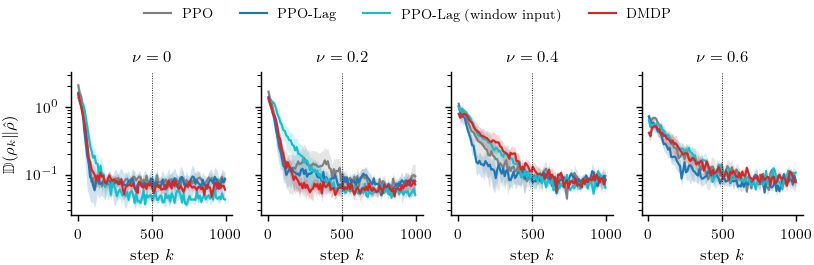

In [5]:
def curve_stats(method, nu):
    Ds = [curves[(method, s, nu)][1] for s in SEEDS if (method, s, nu) in curves]
    c = curves[(method, SEEDS[0], nu)][0]
    Ds = np.array(Ds)
    return c, np.nanmean(Ds, 0), np.nanstd(Ds, 0, ddof=1) / np.sqrt(len(Ds))


def plot_curves(methods, nus, name, ylog=True):
    fig, axes = plt.subplots(1, len(nus), figsize=(TEXTWIDTH, 1.9), sharey=True)
    for ax, nu in zip(np.atleast_1d(axes), nus):
        for m in methods:
            c, mu, se = curve_stats(m, nu)
            ax.plot(c, mu, color=COLORS[m], lw=1.2, label=LABEL[m])
            ax.fill_between(c, mu - se, mu + se, color=COLORS[m], alpha=0.2, lw=0)
        ax.set_xlabel(S_K)
        ax.set_title(rf"$\nu={nu:g}$", fontsize=9)
        if ylog:
            ax.set_yscale("log")
        ax.axvline(K0, color="k", lw=0.5, ls=":")
    np.atleast_1d(axes)[0].set_ylabel(S_D_RHOK)
    h, l = np.atleast_1d(axes)[0].get_legend_handles_labels()
    fig.legend(h, l, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(methods))
    fig.tight_layout(w_pad=0.8)
    save_figure(fig, name)
    return fig


plot_curves(MAIN, [0.0, 0.2, 0.4, 0.6], "stability_curves");

### 5.2 Stable distributions $\hat{\rho}$ and the target $\rho_\star$ (Section 7.2)

Histogram of $v_k$ for $k\ge 500$, pooled over all evaluation episodes and seeds ($\nu=0$), with the target $\rho_\star$ and the threshold $v_{\mathsf{lim}}$.

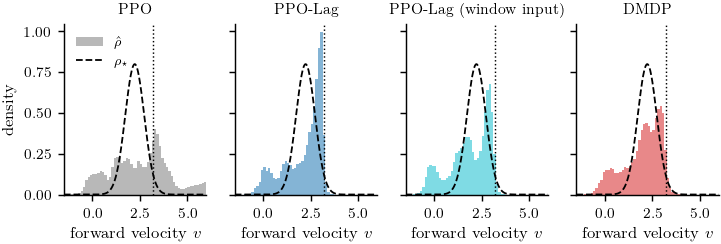

In [6]:
def hist_bins(v, lo=-1.5, hi=6.0, width=0.125):
    # bins of fixed width that cover every sample, so that no sample is dropped from the density
    lo = min(lo, np.floor(np.min(v) / width) * width)
    hi = max(hi, np.ceil(np.max(v) / width) * width)
    return np.arange(lo, hi + width / 2, width)


def pooled_late(method, nu):
    out = []
    for s in SEEDS:
        ev = load_evaluation(ROOT, ENV, method, s)
        if ev is not None:
            out.append(estimate_rho_hat(ev[nu]["velocity"], K0))
    return np.concatenate(out)


def plot_stable_distributions(methods, name, nu=0.0):
    fig, axes = plt.subplots(1, len(methods), figsize=(TEXTWIDTH, 1.7), sharey=True, sharex=True)
    grid = np.linspace(-1.5, 6, 400)
    for ax, m in zip(axes, methods):
        v = pooled_late(m, nu)
        ax.hist(v, bins=hist_bins(v), density=True, color=COLORS[m], alpha=0.55, lw=0, label=S_RHOHAT)
        cfg = load_config(ROOT, ENV, m, SEEDS[0])
        ax.plot(grid, norm.pdf(grid, cfg["mu_star"], cfg["sd_star"]), "k--", lw=1, label=S_RHOSTAR)
        ax.axvline(spec["v_limit"], color="k", lw=0.8, ls=":")
        ax.set_title(LABEL[m], fontsize=8.5)
        ax.set_xlabel(S_V)
        ax.set_xlim(-1.5, 6)
    axes[0].set_ylabel("density")
    axes[0].legend(frameon=False, loc="upper left")
    save_figure(fig, name)
    return fig


plot_stable_distributions(MAIN, "stable_distributions");

### 5.3 Sensor noise (Section 7.3)

Return, cost, residual non-stationarity $\mathbb{D}(\rho_k\|\hat{\rho})$ for $k\ge500$, and distance of the stable distribution to the target, against $\nu$.
Training used $\nu\sim\mathcal{U}[0,0.3]$, so the levels $\nu>0.3$ (shaded) lie outside the training range.

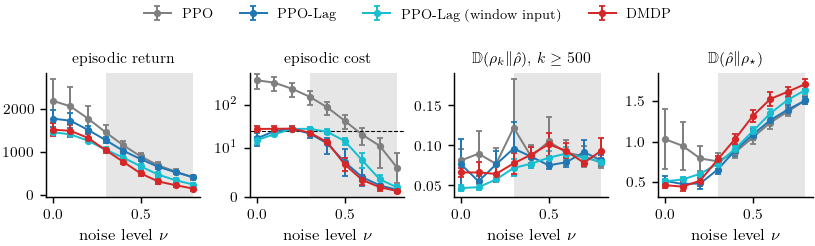

In [7]:
def plot_noise(methods, name):
    panels = [("ret", "episodic return"), ("cost", "episodic cost"),
              ("D_late", S_D_RHOK + r", $k\geq 500$"), ("D_target", S_D_TARGET)]
    fig, axes = plt.subplots(1, 4, figsize=(TEXTWIDTH, 1.75))
    for ax, (key, lab) in zip(axes, panels):
        for m in methods:
            mu, se = mean.loc[m][key], sem.loc[m][key]
            ax.errorbar(mu.index, mu.values, yerr=se.values, color=COLORS[m], lw=1.1, ms=3, marker="o",
                        capsize=1.5, label=LABEL[m])
        if key == "cost":
            ax.axhline(COST_LIMIT, color="k", lw=0.6, ls="--")
            ax.set_yscale("symlog", linthresh=10)
            ax.set_ylim(bottom=0)
        ax.set_xlabel(S_NU)
        ax.set_title(lab, fontsize=8.5)
        ax.axvspan(TRAIN_NOISE_MAX, max(EVAL_NOISES), color="0.9", lw=0, zorder=0)
    h, l = axes[0].get_legend_handles_labels()
    fig.tight_layout(w_pad=0.6)
    fig.legend(h, l, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(methods))
    save_figure(fig, name)
    return fig


plot_noise(MAIN, "noise_sweep");

### 5.4 Stability does not imply reward (Section 7.2)

DMDP with the task-derived target $\rho_\star$ and with a slow target. Both closed loops settle at a stable distribution,
but only the task-derived target yields a high return.

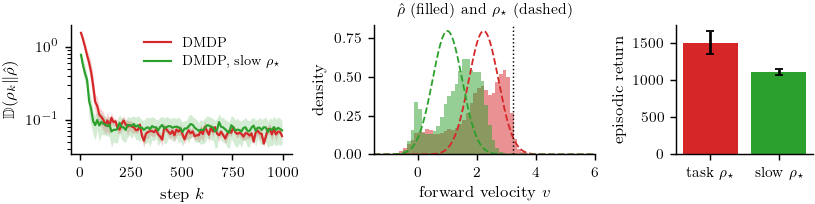

In [8]:
def plot_targets(name, nu=0.0):
    fig, axes = plt.subplots(1, 3, figsize=(TEXTWIDTH, 1.8), gridspec_kw=dict(width_ratios=[1.3, 1.3, 0.8]))
    for m in TARGETS:
        c, mu, se = curve_stats(m, nu)
        axes[0].plot(c, mu, color=COLORS[m], lw=1.2, label=LABEL[m])
        axes[0].fill_between(c, mu - se, mu + se, color=COLORS[m], alpha=0.2, lw=0)
    axes[0].set_yscale("log")
    axes[0].set_xlabel(S_K)
    axes[0].set_ylabel(S_D_RHOK)
    axes[0].legend(frameon=False)
    grid = np.linspace(-1.5, 6, 400)
    for m in TARGETS:
        v = pooled_late(m, nu)
        cfg = load_config(ROOT, ENV, m, SEEDS[0])
        axes[1].hist(v, bins=hist_bins(v), density=True, color=COLORS[m], alpha=0.5, lw=0)
        axes[1].plot(grid, norm.pdf(grid, cfg["mu_star"], cfg["sd_star"]), color=COLORS[m], ls="--", lw=1)
    axes[1].axvline(spec["v_limit"], color="k", lw=0.8, ls=":")
    axes[1].set_xlim(-1.5, 6)
    axes[1].set_xlabel(S_V)
    axes[1].set_ylabel("density")
    axes[1].set_title(S_RHOHAT + r" (filled) and " + S_RHOSTAR + r" (dashed)", fontsize=8.5)
    mu_r = [mean.loc[(m, nu), "ret"] for m in TARGETS]
    se_r = [sem.loc[(m, nu), "ret"] for m in TARGETS]
    axes[2].bar(range(len(TARGETS)), mu_r, yerr=se_r, color=[COLORS[m] for m in TARGETS], capsize=2)
    axes[2].set_xticks(range(len(TARGETS)), [r"task $\rho_\star$", r"slow $\rho_\star$"])
    axes[2].set_ylabel("episodic return")
    fig.tight_layout(w_pad=0.8)
    save_figure(fig, name)
    return fig


plot_targets("targets");

### 5.5 Training curves (Section 7.1)

Episodic return, episodic cost, and training dissimilarity during training. Each logged value is the mean over the
32 most recently completed training episodes; the curves are smoothed further over ten updates.

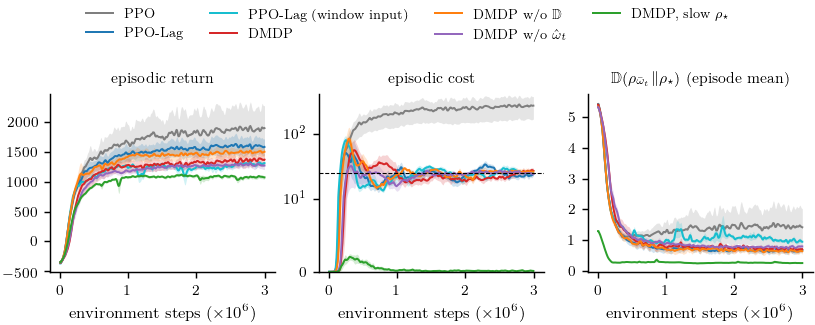

In [9]:
def plot_training(methods, name):
    keys = [("ep_return", "episodic return"), ("ep_cost", "episodic cost"),
            ("ep_dissimilarity", r"$\mathbb{D}(\rho_{\bar{\omega}_t}\|\rho_\star)$ (episode mean)")]
    fig, axes = plt.subplots(1, 3, figsize=(TEXTWIDTH, 2.2))
    for m in methods:
        runs = [load_training(ROOT, ENV, m, s) for s in SEEDS]
        runs = [r for r in runs if r is not None]
        n = min(len(r) for r in runs)
        x = runs[0]["step"].values[:n] / 1e6
        for ax, (key, lab) in zip(axes, keys):
            Y = np.array([r[key].values[:n] for r in runs])
            Y = pd.DataFrame(Y.T).rolling(10, min_periods=1).mean().values.T
            mu, se = Y.mean(0), Y.std(0, ddof=1) / np.sqrt(len(Y))
            ax.plot(x, mu, color=COLORS[m], lw=1.1, label=LABEL[m])
            ax.fill_between(x, mu - se, mu + se, color=COLORS[m], alpha=0.2, lw=0)
            ax.set_title(lab, fontsize=8.5)
            ax.set_xlabel(r"environment steps ($\times 10^6$)")
    axes[1].axhline(COST_LIMIT, color="k", lw=0.6, ls="--")
    axes[1].set_yscale("symlog", linthresh=10)
    axes[1].set_ylim(bottom=0)
    h, l = axes[0].get_legend_handles_labels()
    fig.tight_layout(w_pad=0.6)
    fig.legend(h, l, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4)
    save_figure(fig, name)
    return fig


plot_training(ALL, "training_curves");

## 6 Tables

Mean ± standard error over the five seeds. The LaTeX tables are written to the output folder (`figures/` by default) and are included in the paper with `\input`:
`table_main.tex` (Section 7.2, all seven methods); `table_floor.tex` (Appendix D.2); `table_shift.tex` and `table_beta.tex` (Appendix D.3).

In [10]:
# Bold marks the best mean in a column (for each noise level). "DMDP, slow rho_star" pursues a different target and is
# not compared, and the return is compared only among methods whose mean cost does not exceed the limit.
BOLD_CANDIDATES = ["PPO", "PPO-Lag", "Window-Lag", "DMDP", "DMDP-noD", "State-D"]
COST_LIMIT = 25.0


def fmt_pm(m, s, d=2, bold=False):
    body = f"{m:.{d}f}\\pm{s:.{d}f}"
    return f"$\\bm{{{body}}}$" if bold else f"${body}$"


def best_keys(values, digits, higher):
    # keys whose value, rounded as displayed, is the best (ties are all marked); none if there are no candidates
    shown = {k: round(float(v), digits) for k, v in values.items()}
    if not shown:
        return set()
    best = max(shown.values()) if higher else min(shown.values())
    return {k for k, v in shown.items() if v == best}


# column, decimals, direction (True: higher is better, False: lower is better, None: constraint, not bolded)
MAIN_COLUMNS = [("ret", 0, True), ("cost", 1, None), ("D_early", 2, False), ("D_late", 3, False), ("D_target", 2, False)]


def feasible(table, key, col):
    return col != "ret" or table.loc[key, "cost"] <= COST_LIMIT


def latex_table(methods, nus, name):
    best = {(nu, col): best_keys({m: mean.loc[(m, nu), col] for m in BOLD_CANDIDATES if feasible(mean, (m, nu), col)},
                                 d, hi)
            for nu in nus for col, d, hi in MAIN_COLUMNS if hi is not None}
    rows = []
    for m in methods:
        for nu in nus:
            mu, se = mean.loc[(m, nu)], sem.loc[(m, nu)]
            cells = [fmt_pm(mu[col], se[col], d, bold=hi is not None and m in best[(nu, col)]) for col, d, hi in MAIN_COLUMNS]
            rows.append(" & ".join([LABEL[m] if nu == nus[0] else "", f"${nu:g}$"] + cells) + r" \\")
        rows.append(r"\midrule")
    rows = rows[:-1]
    head = (r"\begin{tabular}{llccccc}" "\n" r"\toprule" "\n"
            r"Method & $\nu$ & return $\uparrow$ & cost ($\leq\bar{c}=25$) & $\mathbb{D}(\rho_k\|\hat{\rho})$, $k<200$ $\downarrow$ & "
            r"$\mathbb{D}(\rho_k\|\hat{\rho})$, $k\geq500$ $\downarrow$ & $\mathbb{D}(\hat{\rho}\|\rho_\star)$ $\downarrow$ \\" "\n" r"\midrule")
    tex = head + "\n" + "\n".join(rows) + "\n" + r"\bottomrule" + "\n" + r"\end{tabular}" + "\n"
    save_table(name, tex)
    return tex


print(latex_table(["PPO", "PPO-Lag", "Window-Lag", "DMDP", "DMDP-noD", "State-D", "DMDP-slow"], [0.0, 0.2], "table_main.tex"))

# shift of the stable distribution caused by sensor noise, D(rho_hat(nu) || rho_hat(0))
SHIFT_NUS = [0.2, 0.4, 0.6, 0.8]
best_shift = {nu: best_keys({m: mean.loc[(m, nu), "D_shift"] for m in BOLD_CANDIDATES}, 2, False) for nu in SHIFT_NUS}
lines = [" & ".join([LABEL[m]] + [fmt_pm(mean.loc[(m, nu), "D_shift"], sem.loc[(m, nu), "D_shift"], bold=m in best_shift[nu])
                                  for nu in SHIFT_NUS]) + r" \\"
         for m in ALL]
tex = (r"\begin{tabular}{lcccc}" "\n" r"\toprule" "\n"
       r" & \multicolumn{4}{c}{$\mathbb{D}(\hat{\rho}_\nu\|\hat{\rho}_0)$ $\downarrow$} \\" "\n" r"\cmidrule(lr){2-5}" "\n"
       r"Method & $\nu=0.2$ & $\nu=0.4$ & $\nu=0.6$ & $\nu=0.8$ \\" "\n" r"\midrule" "\n"
       + "\n".join(lines) + "\n" r"\bottomrule" "\n" r"\end{tabular}" "\n")
save_table("table_shift.tex", tex)
print(tex)

\begin{tabular}{llccccc}
\toprule
Method & $\nu$ & return $\uparrow$ & cost ($\leq\bar{c}=25$) & $\mathbb{D}(\rho_k\|\hat{\rho})$, $k<200$ $\downarrow$ & $\mathbb{D}(\rho_k\|\hat{\rho})$, $k\geq500$ $\downarrow$ & $\mathbb{D}(\hat{\rho}\|\rho_\star)$ $\downarrow$ \\
\midrule
PPO & $0$ & $2180\pm508$ & $361.2\pm135.0$ & $0.43\pm0.08$ & $0.081\pm0.015$ & $1.03\pm0.37$ \\
 & $0.2$ & $1769\pm294$ & $229.9\pm79.0$ & $0.44\pm0.07$ & $0.077\pm0.020$ & $0.79\pm0.15$ \\
\midrule
PPO-Lag & $0$ & $\bm{1768\pm200}$ & $16.8\pm5.7$ & $\bm{0.33\pm0.07}$ & $0.076\pm0.032$ & $0.52\pm0.05$ \\
 & $0.2$ & $1505\pm94$ & $27.9\pm1.4$ & $0.38\pm0.08$ & $0.076\pm0.017$ & $\bm{0.48\pm0.07}$ \\
\midrule
PPO-Lag (window input) & $0$ & $1452\pm44$ & $15.3\pm2.7$ & $0.46\pm0.05$ & $\bm{0.047\pm0.004}$ & $0.51\pm0.03$ \\
 & $0.2$ & $1255\pm38$ & $27.5\pm1.7$ & $0.64\pm0.10$ & $\bm{0.057\pm0.002}$ & $0.60\pm0.03$ \\
\midrule
DMDP & $0$ & $1510\pm157$ & $27.5\pm4.1$ & $0.36\pm0.05$ & $0.066\pm0.006$ & $0.46\pm0.04$ \

### 6.1 Sensitivity to the weight $\beta$ (Section 7.2, Appendix D.3)

DMDP with $\beta\in\{0.25,1,4\}$ (five seeds each). $\beta$ trades the task reward against the dissimilarity to $\rho_\star$.

In [11]:
rows = []
beta_roots = [(0.25, os.path.join(HERE, "results", BETA_TAGS[0.25])), (1.0, ROOT),
              (4.0, os.path.join(HERE, "results", BETA_TAGS[4.0]))]
for beta, root in beta_roots:
    d, _ = summarize(root, ENV, ["DMDP"], SEEDS, k0=K0, block=BLOCK, k_early=K_EARLY)
    d["beta"] = beta
    rows.append(d)
dfb = pd.concat(rows)
mb = dfb.groupby(["beta", "nu"]).mean(numeric_only=True)
sb = dfb.groupby(["beta", "nu"]).sem(numeric_only=True)
BETAS = [0.25, 1.0, 4.0]
best_beta = {(nu, col): best_keys({b: mb.loc[(b, nu), col] for b in BETAS if feasible(mb, (b, nu), col)}, d, hi)
             for nu in [0.0, 0.2] for col, d, hi in MAIN_COLUMNS if hi is not None}
lines = []
for beta in BETAS:
    for nu in [0.0, 0.2]:
        mu, se = mb.loc[(beta, nu)], sb.loc[(beta, nu)]
        cells = [fmt_pm(mu[col], se[col], d, bold=hi is not None and beta in best_beta[(nu, col)]) for col, d, hi in MAIN_COLUMNS]
        lines.append(" & ".join([f"${beta:g}$" if nu == 0.0 else "", f"${nu:g}$"] + cells
                                + [fmt_pm(mu.mu_hat, se.mu_hat), fmt_pm(mu.sd_hat, se.sd_hat)]) + r" \\")
tex = (r"\begin{tabular}{llccccccc}" "\n" r"\toprule" "\n"
       r"$\beta$ & $\nu$ & return $\uparrow$ & cost ($\leq\bar{c}=25$) & $\mathbb{D}(\rho_k\|\hat{\rho})$, $k<200$ $\downarrow$ & "
       r"$\mathbb{D}(\rho_k\|\hat{\rho})$, $k\geq500$ $\downarrow$ & $\mathbb{D}(\hat{\rho}\|\rho_\star)$ $\downarrow$ & "
       r"mean of $\hat{\rho}$ & std of $\hat{\rho}$ \\" "\n" r"\midrule" "\n"
       + "\n".join(lines) + "\n" r"\bottomrule" "\n" r"\end{tabular}" "\n")
save_table("table_beta.tex", tex)
print(tex)

\begin{tabular}{llccccccc}
\toprule
$\beta$ & $\nu$ & return $\uparrow$ & cost ($\leq\bar{c}=25$) & $\mathbb{D}(\rho_k\|\hat{\rho})$, $k<200$ $\downarrow$ & $\mathbb{D}(\rho_k\|\hat{\rho})$, $k\geq500$ $\downarrow$ & $\mathbb{D}(\hat{\rho}\|\rho_\star)$ $\downarrow$ & mean of $\hat{\rho}$ & std of $\hat{\rho}$ \\
\midrule
$0.25$ & $0$ & $\bm{1448\pm31}$ & $23.3\pm3.8$ & $0.42\pm0.04$ & $\bm{0.049\pm0.002}$ & $0.48\pm0.02$ & $1.86\pm0.03$ & $1.05\pm0.03$ \\
 & $0.2$ & $1290\pm46$ & $26.8\pm1.4$ & $0.45\pm0.02$ & $\bm{0.059\pm0.003}$ & $0.57\pm0.03$ & $1.71\pm0.04$ & $1.07\pm0.02$ \\
$1$ & $0$ & $1510\pm157$ & $27.5\pm4.1$ & $\bm{0.36\pm0.05}$ & $0.066\pm0.006$ & $\bm{0.46\pm0.04}$ & $1.95\pm0.15$ & $0.91\pm0.11$ \\
 & $0.2$ & $1320\pm107$ & $28.0\pm3.5$ & $\bm{0.42\pm0.05}$ & $0.064\pm0.010$ & $\bm{0.52\pm0.07}$ & $1.75\pm0.09$ & $0.98\pm0.04$ \\
$4$ & $0$ & $1282\pm160$ & $22.1\pm4.1$ & $0.38\pm0.04$ & $0.067\pm0.008$ & $0.52\pm0.10$ & $1.76\pm0.13$ & $0.94\pm0.08$ \\
 & $0.2$ & $\bm{1

## 7 Sanity checks

**Sampling floor of the evaluation metric (Appendix D.2).** With 32 episodes per half and blocks of 10 steps, even a perfectly stationary process has
$\mathbb{D}(\rho_k\|\hat{\rho})>0$ because of sampling. `metrics.sampling_floor` estimates this floor by applying the same estimator to a surrogate
that is stationary by construction: the late segment ($k\ge500$) of every episode is shifted circularly in time by an independent random amount.
The surrogate has the same $\hat{\rho}$, the same differences between episodes and the same correlation between consecutive steps as the data,
and the floor is averaged over 10 such surrogates. A ratio `D_late / floor` close to one means that $\rho_k$ is stationary in the late steps up to
sampling error; a ratio clearly above one means that $\rho_k$ still changes, for example because the episodes oscillate in phase.

In [12]:
FLOOR_NUS = [0.0, 0.2, 0.4, 0.6, 0.8]
rows = []
for m in ALL:
    for nu in FLOOR_NUS:
        # one generator per (method, seed, nu), so that each value does not depend on the other cells
        floors = [sampling_floor(load_evaluation(ROOT, ENV, m, s)[nu]["velocity"], K0, BLOCK,
                                 np.random.default_rng([ALL.index(m), s, round(10 * nu)])) for s in SEEDS]
        rows.append(dict(method=m, nu=nu, floor=np.mean(floors), D_late=mean.loc[(m, nu), "D_late"]))
floor = pd.DataFrame(rows).set_index(["method", "nu"])
floor["ratio"] = floor["D_late"] / floor["floor"]
lines = [" & ".join([LABEL[m]] + [f"${floor.loc[(m, nu), 'ratio']:.2f}$" for nu in FLOOR_NUS]) + r" \\" for m in ALL]
tex = (r"\begin{tabular}{l*{5}{>{\centering\arraybackslash}p{1.25cm}}}" "\n" r"\toprule" "\n"
       r" & \multicolumn{5}{c}{late-time dissimilarity / sampling floor} \\" "\n" r"\cmidrule(lr){2-6}" "\n"
       r"Method & " + " & ".join(rf"$\nu={nu:g}$" for nu in FLOOR_NUS) + r" \\" "\n" r"\midrule" "\n"
       + "\n".join(lines) + "\n" r"\bottomrule" "\n" r"\end{tabular}" "\n")
save_table("table_floor.tex", tex)
floor.round(3)

floor  D_late  ratio
method     nu                       
PPO        0.0  0.075   0.081  1.084
           0.2  0.074   0.077  1.035
           0.4  0.081   0.086  1.064
           0.6  0.085   0.091  1.071
           0.8  0.079   0.078  0.993
PPO-Lag    0.0  0.070   0.076  1.086
           0.2  0.072   0.076  1.061
           0.4  0.083   0.086  1.041
           0.6  0.077   0.079  1.021
           0.8  0.078   0.081  1.046
Window-Lag 0.0  0.047   0.047  0.988
           0.2  0.055   0.057  1.042
           0.4  0.073   0.077  1.053
           0.6  0.085   0.090  1.055
           0.8  0.076   0.080  1.052
DMDP       0.0  0.065   0.066  1.013
           0.2  0.064   0.064  1.008
           0.4  0.082   0.088  1.085
           0.6  0.090   0.093  1.037
           0.8  0.091   0.093  1.024
DMDP-noD   0.0  0.054   0.082  1.520
           0.2  0.064   0.071  1.106
           0.4  0.077   0.076  0.985
           0.6  0.080   0.079  0.991
           0.8  0.085   0.085  0.998
State-D    0.0  0.055   0.076  1.386
           0.2  0.069   0.069  1.010
           0.4  0.072   0.070  0.980
           0.6  0.078   0.081  1.044
           0.8  0.070   0.073  1.038
DMDP-slow  0.0  0.074   0.077  1.040
           0.2  0.049   0.050  1.018
           0.4  0.062   0.062  1.003
           0.6  0.078   0.083  1.075
           0.8  0.065   0.066  1.018

**Stationarity test of each run (Section 7.2, Appendix D.2).** For each trained policy and noise level, the late-time value of
$\mathbb{D}(\rho_k\|\hat{\rho})$ is compared with its values on 60 independently drawn circular-shift surrogates; the one-sided $p$-value is
$(1+n_{\geq})/61$, where $n_{\geq}$ counts the surrogates whose late-time value is at least that of the run (smallest attainable value $1/61$).

In [13]:
NULL_DRAWS = 60
rows = []
for m in ALL:
    for nu in FLOOR_NUS:
        for s in SEEDS:
            v = load_evaluation(ROOT, ENV, m, s)[nu]["velocity"]
            c, D, _ = stability_curve(v, k0=K0, block=BLOCK)
            late = np.nanmean(D[c >= K0])
            f = sampling_floor(v, K0, BLOCK, np.random.default_rng([ALL.index(m), s, round(10 * nu)]))
            rng = np.random.default_rng([99, ALL.index(m), s, round(10 * nu)])
            null = np.array([sampling_floor(v, K0, BLOCK, rng, draws=1) for _ in range(NULL_DRAWS)])
            rows.append(dict(method=m, seed=s, nu=nu, ratio=late / f, p_value=(1 + np.sum(null >= late)) / (1 + NULL_DRAWS)))
tests = pd.DataFrame(rows).set_index(["method", "seed", "nu"])
rejected = tests[tests.p_value < 0.05]
print(f"stationarity rejected at the 5% level in {len(rejected)} of {len(tests)} runs "
      f"(about {len(tests) * 3 / (NULL_DRAWS + 1):.1f} expected by chance); "
      f"{(rejected.ratio < 1.3).sum()} of them with a ratio below 1.3")
rejected.sort_values("ratio", ascending=False).round(3)

stationarity rejected at the 5% level in 37 of 175 runs (about 8.6 expected by chance); 30 of them with a ratio below 1.3


ratio  p_value
method     seed nu                 
DMDP-noD   4    0.0  2.630    0.016
           2    0.0  2.495    0.016
State-D    1    0.0  2.222    0.016
PPO-Lag    1    0.0  1.643    0.016
DMDP-noD   4    0.2  1.450    0.016
PPO-Lag    1    0.2  1.369    0.016
State-D    3    0.0  1.347    0.016
DMDP       3    0.4  1.296    0.016
DMDP-slow  3    0.0  1.269    0.016
PPO        3    0.0  1.262    0.033
State-D    0    0.0  1.258    0.016
DMDP-slow  4    0.6  1.250    0.016
Window-Lag 3    0.6  1.225    0.016
           4    0.8  1.189    0.016
PPO-Lag    0    0.8  1.186    0.016
Window-Lag 3    0.4  1.180    0.016
DMDP-noD   2    0.2  1.176    0.016
PPO-Lag    0    0.4  1.173    0.016
State-D    3    0.8  1.166    0.016
PPO        0    0.4  1.166    0.049
                0.6  1.163    0.016
DMDP-slow  4    0.0  1.163    0.033
PPO        1    0.0  1.163    0.016
State-D    1    0.6  1.156    0.016
           2    0.0  1.135    0.033
PPO-Lag    2    0.2  1.130    0.049
Window-Lag 4    0.6  1.097    0.016
PPO-Lag    0    0.0  1.097    0.049
State-D    3    0.4  1.095    0.016
DMDP       3    0.6  1.084    0.016
           2    0.0  1.076    0.049
           0    0.0  1.073    0.033
Window-Lag 3    0.8  1.072    0.049
DMDP       1    0.4  1.059    0.016
           0    0.4  1.056    0.049
PPO-Lag    2    0.0  1.005    0.016
DMDP-slow  1    0.0  1.003    0.033

**Per-seed details quoted in Section 7.2 and Section 7.3.** Noise-free stable distribution per seed, its shift at $\nu=0.4$ and $\nu=0.8$, and the decomposition
of the spread of $v_k$ ($k\ge500$, $\nu=0$) into the average within-episode standard deviation and the standard deviation of the episode means.

In [14]:
rows = []
for m in ALL:
    for s in SEEDS:
        v = load_evaluation(ROOT, ENV, m, s)[0.0]["velocity"][:, K0:]
        r0 = df[(df.method == m) & (df.seed == s) & (df.nu == 0.0)].iloc[0]
        r4 = df[(df.method == m) & (df.seed == s) & (df.nu == 0.4)].iloc[0]
        r8 = df[(df.method == m) & (df.seed == s) & (df.nu == 0.8)].iloc[0]
        rows.append(dict(method=m, seed=s, mu_hat=r0.mu_hat, sd_hat=r0.sd_hat, shift_nu04=r4.D_shift, shift_nu08=r8.D_shift,
                         within_sd=np.mean(np.std(v, axis=1)), between_sd=np.std(np.mean(v, axis=1))))
per_seed = pd.DataFrame(rows).set_index(["method", "seed"]).round(2)
per_seed.loc[["PPO-Lag", "DMDP", "DMDP-slow"]]

mu_hat  sd_hat  shift_nu04  shift_nu08  within_sd  between_sd
method    seed                                                               
PPO-Lag   0       2.92    0.17        1.74        2.33       0.17        0.02
          1       2.03    0.93        0.51        1.25       0.93        0.02
          2       1.94    1.06        0.47        1.15       0.87        0.56
          3       1.83    1.04        0.54        1.06       1.04        0.04
          4       1.80    1.08        0.59        1.10       1.08        0.03
DMDP      0       1.79    1.02        0.57        1.35       0.88        0.48
          1       1.73    1.05        0.53        1.28       1.05        0.05
          2       1.88    0.91        0.56        1.18       0.90        0.04
          3       2.54    0.48        1.56        2.16       0.43        0.20
          4       1.80    1.07        0.53        1.15       1.03        0.23
DMDP-slow 0       1.36    0.77        0.22        0.83       0.67        0.35
          1       1.24    0.83        0.23        0.79       0.64        0.47
          2       1.34    0.62        0.54        0.97       0.61        0.03
          3       1.39    0.77        0.37        0.91       0.77        0.02
          4       1.43    0.72        0.24        1.25       0.72        0.02

**Episode survival.** HalfCheetah has no termination, so all evaluation episodes last $H=1000$ steps; the check below confirms this.

In [15]:
df.groupby("method")["survival"].min()

method
DMDP          1.0
DMDP-noD      1.0
DMDP-slow     1.0
PPO           1.0
PPO-Lag       1.0
State-D       1.0
Window-Lag    1.0
Name: survival, dtype: float64